
 # YouTube Shorts Virality — Modelling

**Goal:** predict, 6 hours after a Short is published, whether it will be **viral**: in the top 10% of US+CA videos by views at 72 hours.

**Plan:**
1. **Feature engineering:** early performance, engagement, creator, timing, content. Every feature is known 6h after publishing.
2. **Train/test split:**
   - chronological: older videos for training, newer for testing;
   - channels kept separate between training and test;
   - the viral definition and threshold come from training data only;
   - cross-validation inside the training data.
3. **Four experiments** (training population × feature set), all scored on **US+CA** videos:

   | | Baseline: 6h views | All features |
   |---|---|---|
   | **US+CA training** | experiment 1 | experiment 3 |
   | **All-countries training** | experiment 2 | experiment 4 |

4. **Models:** logistic regression, decision tree, random forest and XGBoost, each trained in all four experiments and compared on the same folds.

Loading and feature code live in `shorts_features.py`, so every notebook builds features the same way.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

import shorts_features as sf

COHORT_END = pd.Timestamp("2026-10-29", tz="UTC")   # videos published before this date
TEST_FRACTION = 0.20      # newest 20% of videos by publish time form the test period
EMBARGO_HOURS = 72        # a training video's 72h outcome must be known before the test period starts
VIRAL_QUANTILE = 0.90     # viral = top 10% of US+CA training videos by 72h views
N_SPLITS, N_REPEATS = 5, 3
RUN_FINAL_TEST = True    # keep False until a model has been chosen with cross-validation

TARGET = "views_72h"
pd.set_option("display.max_columns", 50)

## 1. Feature engineering

| Group | Features (all as of 6h) |
|---|---|
| Early performance | log views at 6h, view growth 3h → 6h (log ratio) |
| Engagement | raw like count, raw comment count, likes hidden |
| Engagement alternative | `log1p` like count, `log1p` comment count, likes hidden |
| Creator | log subscribers, channel age, log total channel views, log average views per channel video |
| Timing | hour posted (US Eastern reference clock, as a 24-hour cycle) |
| Content | duration, number of hashtags, title length, emoji count |

The original all-feature experiments continue to use raw engagement counts. Separate experiments replace only those two counts with `log1p` values on the same folds.

Dynamic channel statistics are used only when their recorded timestamp is at or before the video's 6-hour cutoff. Missing likes remain NaN for imputation/native missing-value handling, with a separate `likes_hidden_6h` indicator.

In [3]:
data = sf.load_data()
table, FEATURE_GROUPS = sf.build_model_table(data)

EARLY_FEATURES = FEATURE_GROUPS["early performance"]
RAW_ENGAGEMENT_FEATURES = FEATURE_GROUPS["engagement"]
LOG_ENGAGEMENT_FEATURES = (
    FEATURE_GROUPS["engagement log1p alternative"] + ["likes_hidden_6h"]
)
METADATA_FEATURES = (
    FEATURE_GROUPS["creator"] + FEATURE_GROUPS["timing"] + FEATURE_GROUPS["content"]
)
BASELINE_FEATURES = ["log_views_6h"]
NO_VIEW_FEATURES = RAW_ENGAGEMENT_FEATURES + METADATA_FEATURES
ALL_FEATURES = EARLY_FEATURES + RAW_ENGAGEMENT_FEATURES + METADATA_FEATURES
ALL_FEATURES_LOG = EARLY_FEATURES + LOG_ENGAGEMENT_FEATURES + METADATA_FEATURES
FEATURE_CHECK_FEATURES = list(dict.fromkeys(ALL_FEATURES + ALL_FEATURES_LOG))

model_df = (
    table[table["published_at"] < COHORT_END]
    .dropna(subset=["views_6h"])
    .sort_values("published_at", ignore_index=True)
)
print(f"DATA SNAPSHOT: {data.snapshot_at:%Y-%m-%d %H:%M} UTC ({data.n_snapshot_files} snapshot files)")
print(f"videos with a 72h outcome: {len(table):,}; in cohort with a 6h snapshot: {len(model_df):,} "
      f"({model_df['in_study'].sum():,} US+CA)")
print(f"published {model_df['published_at'].min():%Y-%m-%d %H:%M} → {model_df['published_at'].max():%Y-%m-%d %H:%M} UTC")
display(pd.Series({
    "early performance": ", ".join(EARLY_FEATURES),
    "engagement (raw)": ", ".join(RAW_ENGAGEMENT_FEATURES),
    "engagement (log1p alternative)": ", ".join(LOG_ENGAGEMENT_FEATURES),
    "metadata": ", ".join(METADATA_FEATURES),
}, name="features").to_frame())

DATA SNAPSHOT: 2026-11-01 01:36 UTC (440 snapshot files)
videos with a 72h outcome: 25,809; in cohort with a 6h snapshot: 25,345 (2,781 US+CA)
published 2026-10-12 13:00 → 2026-10-28 23:58 UTC


,features
early performance,"log_views_6h, view_growth_3_to_6h"
engagement (raw),"like_count_6h, comment_count_6h, likes_hidden_6h"
engagement (log1p alternative),"log_like_count_6h, log_comment_count_6h, likes..."
metadata,"log_subscribers, channel_age_days, log_channel..."


## 2. Train / test split (chronological, channel-separated)

1. **Test period:** the newest `TEST_FRACTION` of videos by publish time. Only its **US+CA** videos are scored.
2. **Embargo:** the `EMBARGO_HOURS` before the test period are not used. In real use, those videos' 72h outcomes would not be known yet.
3. **Channel separation:** training never includes a video from a channel that appears in the test set.
4. **Training (development) set:** everything older than the embargo, minus test channels.
5. **Viral threshold:** the 90th percentile of 72h views among **US+CA training** videos. Test labels use this same threshold.

test period starts 2026-10-25 02:00 UTC; embargo starts 2026-10-22 02:00 UTC
viral threshold (US+CA training videos): 763,436 views at 72h


,all countries,US+CA,US+CA viral
role,,,
training,14689,1111,112
embargo (unused),5000,521,47
test channel (unused),587,587,80
test period,5069,562,48


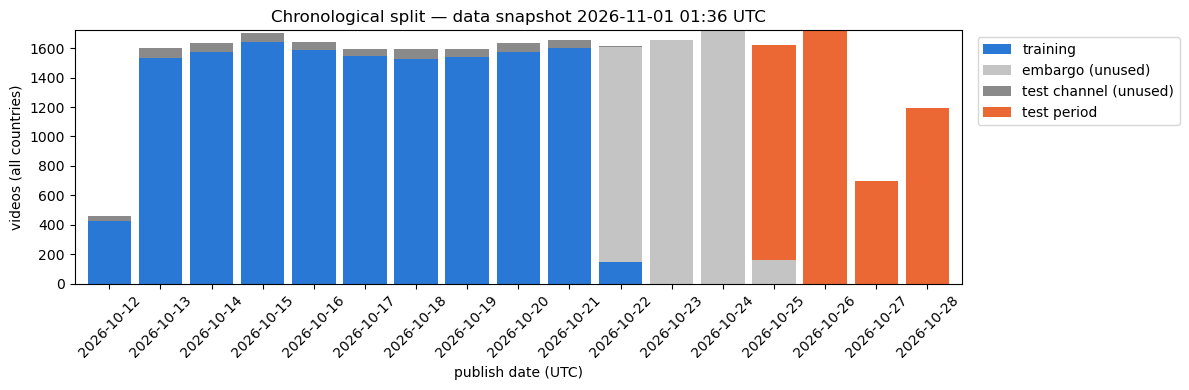

In [4]:
test_start = model_df["published_at"].iloc[int((1 - TEST_FRACTION) * len(model_df))]
embargo_start = test_start - pd.Timedelta(hours=EMBARGO_HOURS)
in_test_period = model_df["published_at"] >= test_start
test = model_df[in_test_period & model_df["in_study"]]

model_df["role"] = np.select(
    [in_test_period, model_df["published_at"] >= embargo_start, model_df["channel_id"].isin(test["channel_id"])],
    ["test period", "embargo (unused)", "test channel (unused)"],
    default="training",
)
dev = model_df[model_df["role"] == "training"].reset_index(drop=True)

threshold = dev.loc[dev["in_study"], TARGET].quantile(VIRAL_QUANTILE)
print(f"test period starts {test_start:%Y-%m-%d %H:%M} UTC; embargo starts {embargo_start:%Y-%m-%d %H:%M} UTC")
print(f"viral threshold (US+CA training videos): {threshold:,.0f} views at 72h")

role_order = ["training", "embargo (unused)", "test channel (unused)", "test period"]
split_table = pd.DataFrame({
    "all countries": model_df["role"].value_counts(),
    "US+CA": model_df.loc[model_df["in_study"], "role"].value_counts(),
    "US+CA viral": model_df.loc[model_df["in_study"]].groupby("role")[TARGET].apply(lambda v: int((v >= threshold).sum())),
}).reindex(role_order).fillna(0).astype(int)
display(split_table)

daily = model_df.groupby([model_df["published_at"].dt.date, "role"]).size().unstack(fill_value=0).reindex(columns=role_order, fill_value=0)
colors = {"training": "#2a78d6", "embargo (unused)": "#c4c4c4", "test channel (unused)": "#8a8a8a", "test period": "#eb6834"}
ax = daily.plot(kind="bar", stacked=True, figsize=(12, 4), width=0.85, color=[colors[r] for r in daily.columns])
ax.set(xlabel="publish date (UTC)", ylabel="videos (all countries)",
       title=f"Chronological split — data snapshot {data.snapshot_at:%Y-%m-%d %H:%M} UTC")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### Feature and leakage checks on training data

The feature summary uses training data only. The checks below also verify the three main leakage risks:

- feature snapshots are selected using exact timestamps and never after 3h/6h;
- time-varying channel statistics are recorded by the 6h cutoff or masked as missing;
- a missing like count is preserved as NaN and represented by `likes_hidden_6h` rather than converted to zero.

In [5]:
dev_us = dev[dev["in_study"]]
group_of = {col: group for group, cols in FEATURE_GROUPS.items() for col in cols}
group_of["likes_hidden_6h"] = "engagement"
feature_check = pd.DataFrame({
    "group": pd.Series(group_of),
    "non-missing % (training)": dev[FEATURE_CHECK_FEATURES].notna().mean().mul(100),
    "median (training)": dev[FEATURE_CHECK_FEATURES].median(),
    "Spearman with 72h views (US+CA training)": dev_us[FEATURE_CHECK_FEATURES].corrwith(
        dev_us[TARGET], method="spearman"
    ),
}).loc[FEATURE_CHECK_FEATURES]
display(feature_check.round(3))

age_3h = model_df["feature_age_3h"].dropna()
age_6h = model_df["feature_age_6h"].dropna()
unsafe_channel = ~model_df["channel_stats_available_by_6h"]
dynamic_channel_features = ["log_subscribers", "log_channel_views", "log_channel_avg_views"]

assert age_3h.between(2, 3).all()
assert age_6h.between(5, 6).all()
assert (model_df["feature_observed_at_6h"] <= model_df["published_at"] + pd.Timedelta(hours=6)).all()
assert model_df.loc[unsafe_channel, dynamic_channel_features].isna().all().all()
assert (
    model_df["likes_hidden_6h"].astype(bool) == model_df["like_count_6h"].isna()
).all()

leakage_audit = pd.Series({
    "3h snapshots after 3h": int((age_3h > 3).sum()),
    "6h snapshots after 6h": int((age_6h > 6).sum()),
    "videos with channel stats recorded after 6h (stats masked)": int(unsafe_channel.sum()),
    "missing/hidden likes at 6h": int(model_df["like_count_6h"].isna().sum()),
    "missing comments at 6h": int(model_df["comment_count_6h"].isna().sum()),
}, name="count")
display(leakage_audit.to_frame())

,group,non-missing % (training),median (training),Spearman with 72h views (US+CA training)
log_views_6h,early performance,100.000,10.030,0.827
view_growth_3_to_6h,early performance,99.523,0.788,0.395
like_count_6h,engagement,87.562,479.000,0.761
comment_count_6h,engagement,99.224,4.000,0.379
likes_hidden_6h,engagement,100.000,0.000,-0.023
log_subscribers,creator,100.000,12.409,0.272
channel_age_days,creator,100.000,1306.069,-0.079
log_channel_views,creator,100.000,19.118,0.331
log_channel_avg_views,creator,100.000,12.342,0.529
pub_hour_sin,timing,100.000,0.000,0.126


,count
3h snapshots after 3h,0
6h snapshots after 6h,0
videos with channel stats recorded after 6h (stats masked),0
missing/hidden likes at 6h,3191
missing comments at 6h,186


## 3. Cross-validation folds

`StratifiedGroupKFold` on the training set, grouped by channel (a creator's videos never sit in both training and validation) and balanced on the viral rate, repeated `N_REPEATS` times.

All four experiments use **the same folds**, so they can be compared fold by fold:
- each fold's viral threshold is recomputed from that fold's US+CA training videos;
- validation is always the fold's US+CA videos;
- only the training rows change between experiments.

In [6]:
y_dev = dev[TARGET] >= threshold   # only used to balance the folds

def cv_folds(n_repeats=N_REPEATS):
    # Yields (repeat, fold, training rows [all countries], US+CA validation rows, fold threshold).
    for repeat in range(n_repeats):
        folds = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=repeat)
        for fold, (train_idx, val_idx) in enumerate(folds.split(dev, y_dev, groups=dev["channel_id"])):
            train, val = dev.iloc[train_idx], dev.iloc[val_idx]
            fold_threshold = train.loc[train["in_study"], TARGET].quantile(VIRAL_QUANTILE)
            yield repeat, fold, train, val[val["in_study"]], fold_threshold

fold_table = pd.DataFrame([
    {"repeat": r, "fold": f,
     "train: all countries": len(train), "train: US+CA": int(train["in_study"].sum()),
     "train US+CA viral": int((train.loc[train["in_study"], TARGET] >= t).sum()),
     "validation: US+CA": len(val), "validation viral": int((val[TARGET] >= t).sum()),
     "threshold": round(t)}
    for r, f, train, val, t in cv_folds()
])
display(fold_table[fold_table["repeat"] == 0])
display(fold_table.drop(columns=["repeat", "fold"]).agg(["min", "mean", "max"]).round(0))

,repeat,fold,train: all countries,train: US+CA,train US+CA viral,validation: US+CA,validation viral,threshold
0,0,0,11750,893,90,218,35,612702
1,0,1,11750,877,88,234,19,790434
2,0,2,11752,893,90,218,20,770269
3,0,3,11752,903,91,208,21,760943
4,0,4,11752,878,88,233,18,791120


,train: all countries,train: US+CA,train US+CA viral,validation: US+CA,validation viral,threshold
min,11750.0,854.0,86.0,200.0,13.0,612702.0
mean,11751.0,889.0,89.0,222.0,23.0,745035.0
max,11752.0,911.0,92.0,257.0,35.0,802772.0


## 4. Experiments

The first four experiments are unchanged. Six additions test view-free feature sets and the engagement transformation.

| # | Training population | Features |
|---|---|---|
| 1 | US+CA | baseline: log views at 6h |
| 2 | All countries | baseline: log views at 6h |
| 3 | US+CA | all features, raw likes/comments |
| 4 | All countries | all features, raw likes/comments |
| 5 | US+CA | metadata only: creator + timing + content |
| 6 | All countries | metadata only: creator + timing + content |
| 7 | US+CA | no view features: engagement + metadata |
| 8 | All countries | no view features: engagement + metadata |
| 9 | US+CA | all features, `log1p` likes/comments |
| 10 | All countries | all features, `log1p` likes/comments |

Every experiment is scored on the same US+CA validation folds. This makes population, ablation, and raw-vs-log differences paired within each fold.

In [7]:
EXPERIMENTS = {
    "1. US+CA, baseline": ("US+CA", BASELINE_FEATURES),
    "2. All countries, baseline": ("All countries", BASELINE_FEATURES),
    "3. US+CA, all features (raw engagement)": ("US+CA", ALL_FEATURES),
    "4. All countries, all features (raw engagement)": ("All countries", ALL_FEATURES),
    "5. US+CA, metadata only": ("US+CA", METADATA_FEATURES),
    "6. All countries, metadata only": ("All countries", METADATA_FEATURES),
    "7. US+CA, no view features": ("US+CA", NO_VIEW_FEATURES),
    "8. All countries, no view features": ("All countries", NO_VIEW_FEATURES),
    "9. US+CA, all features (log1p engagement)": ("US+CA", ALL_FEATURES_LOG),
    "10. All countries, all features (log1p engagement)": ("All countries", ALL_FEATURES_LOG),
}

def training_rows(frame, population):
    return frame[frame["in_study"]] if population == "US+CA" else frame

display(pd.DataFrame([
    {"experiment": name, "training population": population, "features": len(features),
     "training videos": len(training_rows(dev, population)),
     "training viral": int((training_rows(dev, population)[TARGET] >= threshold).sum())}
    for name, (population, features) in EXPERIMENTS.items()
]).set_index("experiment"))

,training population,features,training videos,training viral
experiment,,,,
"1. US+CA, baseline",US+CA,1,1111,112
"2. All countries, baseline",All countries,1,14689,1342
"3. US+CA, all features (raw engagement)",US+CA,15,1111,112
"4. All countries, all features (raw engagement)",All countries,15,14689,1342
"5. US+CA, metadata only",US+CA,10,1111,112
"6. All countries, metadata only",All countries,10,14689,1342
"7. US+CA, no view features",US+CA,13,1111,112
"8. All countries, no view features",All countries,13,14689,1342
"9. US+CA, all features (log1p engagement)",US+CA,15,1111,112


### Evaluation harness

`run_experiments` trains every fixed model in every experiment on identical channel-grouped folds and scores it on the same US+CA validation rows.

**Metrics:**
- **PR-AUC:** main metric; its random baseline is the viral rate (~0.10).
- **ROC-AUC.**
- **precision@10% / recall@10%:** select exactly `ceil(10% × n)` validation videos. Scores are ordered descending and ties are broken deterministically by `video_id`, so tied probabilities cannot inflate the flagged set.

In [8]:
METRICS = ["PR-AUC", "ROC-AUC", "precision@10%", "recall@10%"]

def top_fraction_mask(scores, tie_breaker, fraction=0.10):
    scores = np.asarray(scores, dtype=float)
    tie_breaker = np.asarray(tie_breaker).astype(str)
    if len(scores) != len(tie_breaker) or not np.isfinite(scores).all():
        raise ValueError("Scores and tie breakers must be aligned and scores must be finite")
    k = max(1, int(np.ceil(fraction * len(scores))))
    order = np.lexsort((tie_breaker, -scores))
    flagged = np.zeros(len(scores), dtype=bool)
    flagged[order[:k]] = True
    return flagged

def score(y_true, scores, tie_breaker):
    y_true = np.asarray(y_true, dtype=bool)
    flagged = top_fraction_mask(scores, tie_breaker)
    hits = np.logical_and(flagged, y_true).sum()
    return {"PR-AUC": average_precision_score(y_true, scores),
            "ROC-AUC": roc_auc_score(y_true, scores),
            "precision@10%": hits / flagged.sum(),
            "recall@10%": hits / y_true.sum()}

def run_experiments(models, experiments=EXPERIMENTS, n_repeats=N_REPEATS):
    rows = []
    for repeat, fold, train, val, fold_threshold in cv_folds(n_repeats):
        y_val = (val[TARGET] >= fold_threshold).to_numpy()
        for experiment, (population, features) in experiments.items():
            train_exp = training_rows(train, population)
            y_train = (train_exp[TARGET] >= fold_threshold).astype(int)
            for model_name, model in models.items():
                fitted = clone(model).fit(train_exp[features], y_train)
                probabilities = fitted.predict_proba(val[features])[:, 1]
                rows.append({"experiment": experiment, "model": model_name,
                             "repeat": repeat, "fold": fold,
                             **score(y_val, probabilities, val["video_id"])})
    return pd.DataFrame(rows)

def summarize(results):
    stats = results.groupby(["experiment", "model"], sort=False)[METRICS].agg(["mean", "std"])
    return pd.DataFrame({m: stats[(m, "mean")].map("{:.3f}".format) + " ± " + stats[(m, "std")].map("{:.3f}".format)
                         for m in METRICS})

## 5. Models

| Model | Missing values | Starting settings |
|---|---|---|
| Logistic regression | median imputation + missing-value indicators, then standardised | L2 penalty |
| Decision tree | handled natively by scikit-learn trees | depth-limited, at least 50 videos per leaf |
| Random forest | handled natively | 300 trees, √features per split |
| XGBoost | handled natively | 300 shallow trees, learning rate 0.05, row/column subsampling |

Each model is kept deliberately simple: the training set has only a few hundred US+CA viral videos, so heavily tuned or deep models would overfit.

In [9]:
BASE_MODELS = {
    "Logistic regression": make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LogisticRegression(max_iter=2000)),
    "Decision tree": DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=0),
    "Random forest": RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=20,
                                            n_jobs=-1, random_state=0),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=5,
                             subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                             eval_metric="logloss", n_jobs=-1, random_state=0),
}
MODEL_COLORS = dict(zip(BASE_MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

## 6. Fair comparison with fixed models

All ten experiments use the same untuned starting settings. The first four original experiments, four feature ablations, and two engagement transformations are therefore directly comparable on paired folds.

We first select an experiment and model using these fixed settings. Only that selected setup is tuned afterward on the development folds; the locked chronological test remains the final evaluation.

In [10]:
cv_results = run_experiments(BASE_MODELS)
print(f"{N_REPEATS} × {N_SPLITS}-fold grouped CV; data snapshot {data.snapshot_at:%Y-%m-%d %H:%M} UTC")
display(summarize(cv_results))

print("Mean PR-AUC (rows: model, columns: experiment):")
display(cv_results.pivot_table(index="model", columns="experiment", values="PR-AUC", sort=False).round(3))

3 × 5-fold grouped CV; data snapshot 2026-11-01 01:36 UTC


PR-AUC  \
experiment                                         model                                
1. US+CA, baseline                                 Logistic regression  0.697 ± 0.139   
                                                   Decision tree        0.537 ± 0.157   
                                                   Random forest        0.666 ± 0.142   
                                                   XGBoost              0.648 ± 0.141   
2. All countries, baseline                         Logistic regression  0.697 ± 0.139   
                                                   Decision tree        0.653 ± 0.155   
                                                   Random forest        0.670 ± 0.149   
                                                   XGBoost              0.686 ± 0.146   
3. US+CA, all features (raw engagement)            Logistic regression  0.684 ± 0.139   
                                                   Decision tree        0.526 ± 0.153   
                                                   Random forest        0.668 ± 0.162   
                                                   XGBoost              0.651 ± 0.130   
4. All countries, all features (raw engagement)    Logistic regression  0.713 ± 0.134   
                                                   Decision tree        0.648 ± 0.142   
                                                   Random forest        0.732 ± 0.132   
                                                   XGBoost              0.752 ± 0.114   
5. US+CA, metadata only                            Logistic regression  0.264 ± 0.092   
                                                   Decision tree        0.210 ± 0.073   
                                                   Random forest        0.267 ± 0.072   
                                                   XGBoost              0.246 ± 0.083   
6. All countries, metadata only                    Logistic regression  0.300 ± 0.078   
                                                   Decision tree        0.268 ± 0.085   
                                                   Random forest        0.302 ± 0.098   
                                                   XGBoost              0.287 ± 0.083   
7. US+CA, no view features                         Logistic regression  0.513 ± 0.168   
                                                   Decision tree        0.352 ± 0.122   
                                                   Random forest        0.505 ± 0.147   
                                                   XGBoost              0.492 ± 0.120   
8. All countries, no view features                 Logistic regression  0.529 ± 0.189   
                                                   Decision tree        0.537 ± 0.153   
                                                   Random forest        0.579 ± 0.153   
                                                   XGBoost              0.597 ± 0.138   
9. US+CA, all features (log1p engagement)          Logistic regression  0.683 ± 0.125   
                                                   Decision tree        0.526 ± 0.153   
                                                   Random forest        0.668 ± 0.162   
                                                   XGBoost              0.651 ± 0.130   
10. All countries, all features (log1p engagement) Logistic regression  0.726 ± 0.130   
                                                   Decision tree        0.648 ± 0.142   
                                                   Random forest        0.732 ± 0.132   
                                                   XGBoost              0.752 ± 0.114   

                                                                              ROC-AUC  \
experiment                                         model                                
1. US+CA, baseline                                 Logistic regression  0.921 ± 0.033   
                                                   Decision tree        0

Mean PR-AUC (rows: model, columns: experiment):


experiment,"1. US+CA, baseline","2. All countries, baseline","3. US+CA, all features (raw engagement)","4. All countries, all features (raw engagement)","5. US+CA, metadata only","6. All countries, metadata only","7. US+CA, no view features","8. All countries, no view features","9. US+CA, all features (log1p engagement)","10. All countries, all features (log1p engagement)"
model,,,,,,,,,,
Logistic regression,0.697,0.697,0.684,0.713,0.264,0.300,0.513,0.529,0.683,0.726
Decision tree,0.537,0.653,0.526,0.648,0.210,0.268,0.352,0.537,0.526,0.648
Random forest,0.666,0.670,0.668,0.732,0.267,0.302,0.505,0.579,0.668,0.732
XGBoost,0.648,0.686,0.651,0.752,0.246,0.287,0.492,0.597,0.651,0.752


### Select the setup, then tune only that setup

The fixed-model comparison chooses the experiment and model with the highest mean PR-AUC. We then tune one main setting for that selected model using development cross-validation only.

The fixed-model scores above are the fair comparison across experiments. The tuning scores below guide configuration selection; they are not a substitute for the locked chronological test.

In [11]:
mean_scores = cv_results.groupby(["experiment", "model"], sort=False)["PR-AUC"].mean()
best_mean = mean_scores.max()
tied_best = mean_scores[(best_mean - mean_scores).abs() <= 1e-12]
CHOSEN_EXPERIMENT, CHOSEN_MODEL = tied_best.index[0]  # experiment order breaks exact ties
if len(tied_best) > 1:
    print(f"{len(tied_best)} setups tied exactly; preferring the earliest predefined experiment.")
print(f"Selected from the fixed-model comparison: {CHOSEN_MODEL} in '{CHOSEN_EXPERIMENT}'")

TUNING_GRID = {
    "Logistic regression": ("logisticregression__C", [0.1, 1.0, 10.0]),
    "Decision tree": ("max_depth", [3, 4, 6]),
    "Random forest": ("min_samples_leaf", [5, 20, 50]),
    "XGBoost": ("max_depth", [2, 3, 5]),
}

param, values = TUNING_GRID[CHOSEN_MODEL]
variants = {
    f"{CHOSEN_MODEL}: {value}": clone(BASE_MODELS[CHOSEN_MODEL]).set_params(**{param: value})
    for value in values
}
tuning_results = run_experiments(
    variants,
    experiments={CHOSEN_EXPERIMENT: EXPERIMENTS[CHOSEN_EXPERIMENT]},
)
tuning_stats = tuning_results.groupby("model", sort=False)["PR-AUC"].agg(["mean", "std"])
best_index = int(np.argmax(tuning_stats["mean"].to_numpy()))
best_value = values[best_index]
FINAL_MODEL = clone(BASE_MODELS[CHOSEN_MODEL]).set_params(**{param: best_value})

tuning_table = pd.DataFrame({
    "value": values,
    "PR-AUC mean": tuning_stats["mean"].to_numpy(),
    "PR-AUC sd": tuning_stats["std"].to_numpy(),
    "chosen": [value == best_value for value in values],
}).set_index("value")
print(f"Tuned {param} for the selected setup; chosen value: {best_value}")
display(tuning_table.round(3))

2 setups tied exactly; preferring the earliest predefined experiment.
Selected from the fixed-model comparison: XGBoost in '4. All countries, all features (raw engagement)'
Tuned max_depth for the selected setup; chosen value: 3


,PR-AUC mean,PR-AUC sd,chosen
value,,,
2,0.752,0.113,False
3,0.752,0.114,True
5,0.740,0.122,False


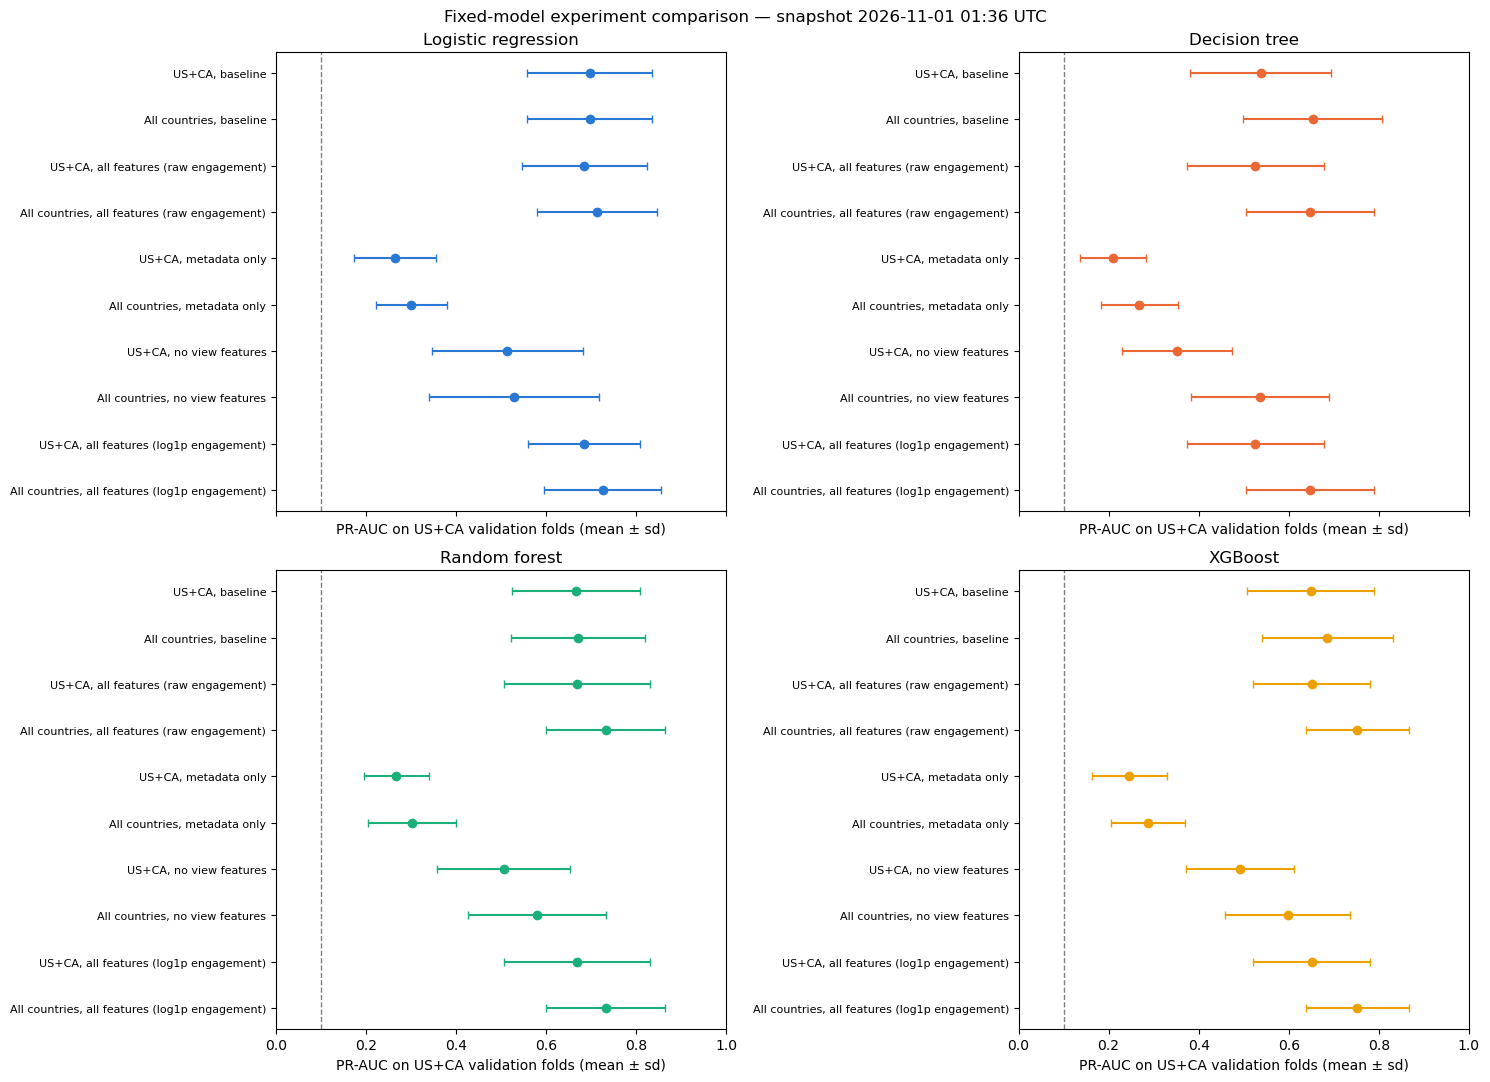

In [12]:
stats = cv_results.groupby(["experiment", "model"], sort=False)["PR-AUC"].agg(["mean", "std"])
experiments = list(EXPERIMENTS)
labels = [name.split(". ", 1)[1] for name in experiments]
fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharex=True)
for ax, model in zip(axes.ravel(), BASE_MODELS):
    s = stats.xs(model, level="model").reindex(experiments)
    y = np.arange(len(experiments))
    ax.errorbar(s["mean"], y, xerr=s["std"], fmt="o", capsize=3, color=MODEL_COLORS[model])
    ax.axvline(1 - VIRAL_QUANTILE, color="gray", ls="--", lw=1)
    ax.set_yticks(y, labels, fontsize=8)
    ax.invert_yaxis()
    ax.set(title=model, xlabel="PR-AUC on US+CA validation folds (mean ± sd)", xlim=(0, 1))
fig.suptitle(f"Fixed-model experiment comparison — snapshot {data.snapshot_at:%Y-%m-%d %H:%M} UTC")
plt.tight_layout()
plt.show()

### Paired experiment comparisons

Folds vary substantially in difficulty, so each comparison subtracts PR-AUC values **within the same repeat, fold, and model** before summarizing.

The comparisons distinguish training-population effects, the contribution of feature bundles, and raw versus `log1p` engagement. These are predictive ablations—not causal or independent effects.

In [13]:
pr = cv_results.pivot_table(index=["repeat", "fold", "model"], columns="experiment", values="PR-AUC")
COMPARISONS = {
    "Worldwide vs US+CA training — all raw features": (
        "4. All countries, all features (raw engagement)",
        "3. US+CA, all features (raw engagement)",
    ),
    "Worldwide vs US+CA training — baseline": (
        "2. All countries, baseline", "1. US+CA, baseline",
    ),
    "All raw features vs baseline — US+CA training": (
        "3. US+CA, all features (raw engagement)", "1. US+CA, baseline",
    ),
    "All raw features vs baseline — worldwide training": (
        "4. All countries, all features (raw engagement)", "2. All countries, baseline",
    ),
    "Add view features to no-view set — US+CA training": (
        "3. US+CA, all features (raw engagement)", "7. US+CA, no view features",
    ),
    "Add view features to no-view set — worldwide training": (
        "4. All countries, all features (raw engagement)", "8. All countries, no view features",
    ),
    "Add engagement to metadata — US+CA training": (
        "7. US+CA, no view features", "5. US+CA, metadata only",
    ),
    "Add engagement to metadata — worldwide training": (
        "8. All countries, no view features", "6. All countries, metadata only",
    ),
    "log1p vs raw engagement — US+CA training": (
        "9. US+CA, all features (log1p engagement)",
        "3. US+CA, all features (raw engagement)",
    ),
    "log1p vs raw engagement — worldwide training": (
        "10. All countries, all features (log1p engagement)",
        "4. All countries, all features (raw engagement)",
    ),
}

comparison_rows = []
for label, (a, b) in COMPARISONS.items():
    for model, diff in (pr[a] - pr[b]).groupby(level="model", sort=False):
        comparison_rows.append({
            "comparison": label, "model": model,
            "mean paired PR-AUC gain": diff.mean(), "sd": diff.std(),
            "folds better": (diff > 0).mean(),
        })
comparison_table = pd.DataFrame(comparison_rows)
display(
    comparison_table.set_index(["comparison", "model"])
    .style.format({"mean paired PR-AUC gain": "{:+.3f}", "sd": "{:.3f}", "folds better": "{:.0%}"})
)

### Feature-group importance through paired ablation

Summed permutation importances can mislead when predictors are correlated: early views, likes, and channel popularity can substitute for one another. Instead, the chart below reports paired PR-AUC changes for the selected model with fixed starting settings.

Each bar is a feature **bundle** comparison on identical folds. The bundles overlap, so they still should not be read as independent or causal contributions.

,mean gain,sd,folds better
comparison,,,
Views added | US+CA training,+0.158,0.037,100%
Views added | worldwide training,+0.155,0.075,100%
Engagement added | US+CA training,+0.246,0.087,100%
Engagement added | worldwide training,+0.310,0.099,100%
All extra features beyond 6h views | US+CA,+0.002,0.080,53%
All extra features beyond 6h views | worldwide,+0.067,0.052,93%


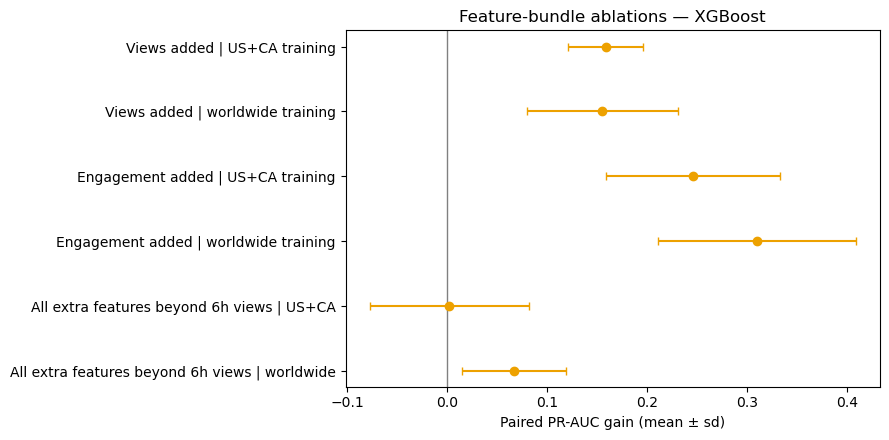

In [14]:
IMPORTANCE_COMPARISONS = {
    "Views added | US+CA training": (
        "3. US+CA, all features (raw engagement)", "7. US+CA, no view features",
    ),
    "Views added | worldwide training": (
        "4. All countries, all features (raw engagement)", "8. All countries, no view features",
    ),
    "Engagement added | US+CA training": (
        "7. US+CA, no view features", "5. US+CA, metadata only",
    ),
    "Engagement added | worldwide training": (
        "8. All countries, no view features", "6. All countries, metadata only",
    ),
    "All extra features beyond 6h views | US+CA": (
        "3. US+CA, all features (raw engagement)", "1. US+CA, baseline",
    ),
    "All extra features beyond 6h views | worldwide": (
        "4. All countries, all features (raw engagement)", "2. All countries, baseline",
    ),
}

selected_pr = pr.xs(CHOSEN_MODEL, level="model")
importance_rows = []
for label, (with_features, without_features) in IMPORTANCE_COMPARISONS.items():
    diff = selected_pr[with_features] - selected_pr[without_features]
    importance_rows.append({"comparison": label, "mean gain": diff.mean(), "sd": diff.std(),
                            "folds better": (diff > 0).mean()})
paired_importance = pd.DataFrame(importance_rows).set_index("comparison")
display(paired_importance.style.format({"mean gain": "{:+.3f}", "sd": "{:.3f}", "folds better": "{:.0%}"}))

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(paired_importance))
ax.errorbar(paired_importance["mean gain"], y, xerr=paired_importance["sd"],
            fmt="o", capsize=3, color=MODEL_COLORS[CHOSEN_MODEL])
ax.axvline(0, color="gray", lw=1)
ax.set_yticks(y, paired_importance.index)
ax.invert_yaxis()
ax.set(xlabel="Paired PR-AUC gain (mean ± sd)", title=f"Feature-bundle ablations — {CHOSEN_MODEL}")
plt.tight_layout()
plt.show()

## 7. Final test (run once, at the end)

The chosen setup is the experiment and model with the highest mean cross-validated PR-AUC. You can override it below, for example to prefer a simpler model when the difference is within noise, but do so **before** running the test.

On the frozen data copy, set `RUN_FINAL_TEST = True` and run the notebook once. The chosen model is refit on the full training set and scored on the held-out US+CA test videos, next to the plain 6h-views rule. Do not change the model after looking at the test result.

In [15]:
print(f"Chosen setup: {CHOSEN_MODEL} in '{CHOSEN_EXPERIMENT}', with {param}={best_value}")

def final_test():
    population, features = EXPERIMENTS[CHOSEN_EXPERIMENT]
    train = training_rows(dev, population)
    fitted = clone(FINAL_MODEL).fit(train[features], (train[TARGET] >= threshold).astype(int))
    y_test = (test[TARGET] >= threshold).to_numpy()
    print(f"Final test — data snapshot {data.snapshot_at:%Y-%m-%d %H:%M} UTC; {len(test):,} US+CA videos, {y_test.sum()} viral")
    test_scores = {
        "rule: views at 6h": test["views_6h"].to_numpy(),
        f"{CHOSEN_MODEL} ({CHOSEN_EXPERIMENT})": fitted.predict_proba(test[features])[:, 1],
    }
    results = pd.DataFrame({
        name: score(y_test, scores, test["video_id"]) for name, scores in test_scores.items()
    }).T.round(3)
    return results, y_test, test_scores

if RUN_FINAL_TEST:
    final_results, y_test, test_scores = final_test()
    display(final_results)
else:
    print("Final test is locked. Set RUN_FINAL_TEST = True on the frozen data copy and run once.")

Chosen setup: XGBoost in '4. All countries, all features (raw engagement)', with max_depth=3
Final test — data snapshot 2026-11-01 01:36 UTC; 562 US+CA videos, 48 viral


,PR-AUC,ROC-AUC,precision@10%,recall@10%
rule: views at 6h,0.685,0.880,0.561,0.667
"XGBoost (4. All countries, all features (raw engagement))",0.757,0.911,0.614,0.729


### ROC and precision-recall curves on the test set

The chosen model against the plain 6h-views rule, on the same held-out US+CA test videos. Dots mark the operating point used in the table above: flag the top 10% of test videos. Dashed lines are random guessing; for precision-recall that is the test viral rate.

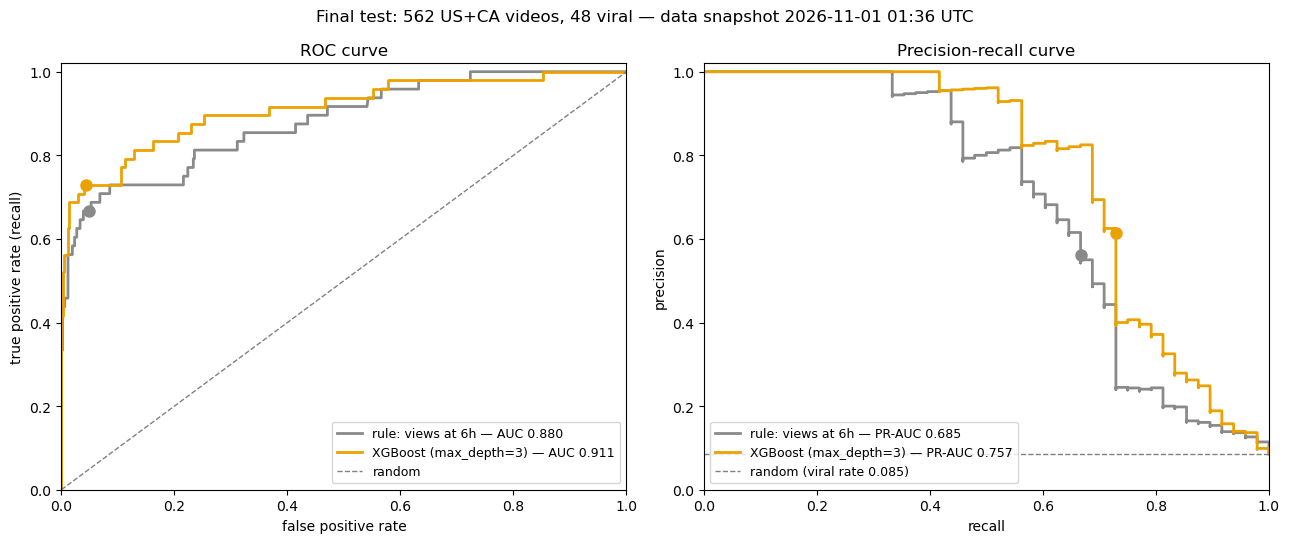

In [16]:
if RUN_FINAL_TEST:
    curve_styles = {
        "rule: views at 6h": ("rule: views at 6h", "#8a8a8a"),
        f"{CHOSEN_MODEL} ({CHOSEN_EXPERIMENT})": (f"{CHOSEN_MODEL} ({param}={best_value})", MODEL_COLORS[CHOSEN_MODEL]),
    }
    fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5.5))
    for name, scores in test_scores.items():
        label, color = curve_styles[name]
        row = final_results.loc[name]
        flagged = top_fraction_mask(scores, test["video_id"])
        false_positive_rate = (flagged & ~y_test).sum() / (~y_test).sum()

        fpr, tpr, _ = roc_curve(y_test, scores)
        ax_roc.plot(fpr, tpr, color=color, lw=2, label=f"{label} — AUC {row['ROC-AUC']:.3f}")
        ax_roc.plot(false_positive_rate, row["recall@10%"], "o", color=color, ms=8)

        precision, recall, _ = precision_recall_curve(y_test, scores)
        ax_pr.plot(recall, precision, color=color, lw=2, drawstyle="steps-post",
                   label=f"{label} — PR-AUC {row['PR-AUC']:.3f}")
        ax_pr.plot(row["recall@10%"], row["precision@10%"], "o", color=color, ms=8)

    ax_roc.plot([0, 1], [0, 1], ls="--", color="gray", lw=1, label="random")
    ax_roc.set(xlabel="false positive rate", ylabel="true positive rate (recall)", title="ROC curve",
               xlim=(0, 1), ylim=(0, 1.02))
    ax_roc.legend(loc="lower right", fontsize=9)
    ax_pr.axhline(y_test.mean(), ls="--", color="gray", lw=1, label=f"random (viral rate {y_test.mean():.3f})")
    ax_pr.set(xlabel="recall", ylabel="precision", title="Precision-recall curve", xlim=(0, 1), ylim=(0, 1.02))
    ax_pr.legend(loc="lower left", fontsize=9)
    fig.suptitle(f"Final test: {len(test):,} US+CA videos, {y_test.sum()} viral — "
                 f"data snapshot {data.snapshot_at:%Y-%m-%d %H:%M} UTC")
    plt.tight_layout()
    plt.show()